# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.feature_selection import SelectKBest, chi2, f_regression
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Loading Dataset

In [2]:
df = pd.read_excel("/kaggle/input/indian-rainfall-and-weather-data/india_weather_rainfall_data.xlsx")

df.to_csv("rainfall.csv", index=False)
df = pd.read_csv("rainfall.csv")
df.head()

,date_of_record,month,season,station_name,state,district,avg_temp,min_temp,max_temp,wind_speed,air_pressure,elevation,latitude,longitude,rainfall
0,2021-01-02,January,Winter,Gulmarg,JK,Baramulla,-2.2,-6.6,-0.8,2.2,1020.0,2652,34.05,74.4,0.1
1,2021-01-03,January,Winter,Gulmarg,JK,Baramulla,-3.6,-4.6,-1.8,3.7,1019.5,2652,34.05,74.4,4.4
2,2021-01-04,January,Winter,Gulmarg,JK,Baramulla,-3.0,-4.5,-1.1,2.1,1022.0,2652,34.05,74.4,2.3
3,2021-01-05,January,Winter,Gulmarg,JK,Baramulla,-3.3,-5.1,-1.2,2.8,1015.6,2652,34.05,74.4,35.0
4,2021-01-06,January,Winter,Gulmarg,JK,Baramulla,-3.9,-8.3,-1.0,3.4,1015.3,2652,34.05,74.4,25.5


# Displaying the Data

In [3]:
df

,date_of_record,month,season,station_name,state,district,avg_temp,min_temp,max_temp,wind_speed,air_pressure,elevation,latitude,longitude,rainfall
0,2021-01-02,January,Winter,Gulmarg,JK,Baramulla,-2.2,-6.6,-0.8,2.2,1020.0,2652,34.0500,74.4000,0.1
1,2021-01-03,January,Winter,Gulmarg,JK,Baramulla,-3.6,-4.6,-1.8,3.7,1019.5,2652,34.0500,74.4000,4.4
2,2021-01-04,January,Winter,Gulmarg,JK,Baramulla,-3.0,-4.5,-1.1,2.1,1022.0,2652,34.0500,74.4000,2.3
3,2021-01-05,January,Winter,Gulmarg,JK,Baramulla,-3.3,-5.1,-1.2,2.8,1015.6,2652,34.0500,74.4000,35.0
4,2021-01-06,January,Winter,Gulmarg,JK,Baramulla,-3.9,-8.3,-1.0,3.4,1015.3,2652,34.0500,74.4000,25.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
970334,2025-02-06,February,Winter,Vizagapatam / Gajuwaka,AP,Visakhapatnam,27.3,22.0,34.0,7.6,1011.4,5,17.7167,83.2333,0.0
970335,2025-02-07,February,Winter,Vizagapatam / Gajuwaka,AP,Visakhapatnam,26.7,23.0,30.0,7.7,1013.1,5,17.7167,83.2333,0.3
970336,2025-02-08,February,Winter,Vizagapatam / Gajuwaka,AP,Visakhapatnam,26.5,23.0,30.0,8.7,1013.0,5,17.7167,83.2333,0.0
970337,2025-02-09,February,Winter,Vizagapatam / Gajuwaka,AP,Visakhapatnam,26.5,23.0,30.0,8.5,1012.8,5,17.7167,83.2333,0.0


# Dimension of the Data

In [4]:
df.shape

(970339, 15)

In [5]:
df.columns

Index(['date_of_record', 'month', 'season', 'station_name', 'state',
       'district', 'avg_temp', 'min_temp', 'max_temp', 'wind_speed',
       'air_pressure', 'elevation', 'latitude', 'longitude', 'rainfall'],
      dtype='object')

# Data Cleaning
* Cleaning Duplicate and Null Values

In [6]:
duplicate_count = df.duplicated().sum()
print(f"Duplicates found: {duplicate_count}")
if duplicate_count > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicates removed.")

Duplicates found: 0


* Checking Missing Values

In [7]:
df.isna().sum()

date_of_record         0
month                  0
season                 0
station_name           0
state                  0
district               0
avg_temp               0
min_temp           43898
max_temp          110598
wind_speed        274444
air_pressure      304664
elevation              0
latitude               0
longitude              0
rainfall          257554
dtype: int64

* Handling Missing Value

In [8]:
df.dropna(subset=['rainfall'], inplace=True)

df.fillna(df.median(numeric_only=True), inplace=True)
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print(f"Data Cleaning Complete. Shape: {df.shape}")

Data Cleaning Complete. Shape: (712785, 15)


In [9]:
df.isna().sum()

date_of_record    0
month             0
season            0
station_name      0
state             0
district          0
avg_temp          0
min_temp          0
max_temp          0
wind_speed        0
air_pressure      0
elevation         0
latitude          0
longitude         0
rainfall          0
dtype: int64

# Feature Selection

In [10]:
df_select = df.copy()

cols_to_drop = ['date_of_record', 'station_name'] 
df_select.drop(columns=[c for c in cols_to_drop if c in df_select.columns], inplace=True)

le_dict = {}
cat_cols = ['season', 'state', 'district', 'month']
for col in cat_cols:
    if col in df_select.columns:
        le = LabelEncoder()
        df_select[col] = le.fit_transform(df_select[col].astype(str))
        le_dict[col] = le


X = df_select.drop('rainfall', axis=1)
y = df_select['rainfall']

# T-Test

In [11]:
print("\nTop Features using T-Test (f_regression):")
selector_f = SelectKBest(score_func=f_regression, k=5)
X_new_f = selector_f.fit_transform(X, y)
selected_indices_f = selector_f.get_support(indices=True)
print("Top 5 Features (T-Test Logic):", X.columns[selected_indices_f].tolist())


Top Features using T-Test (f_regression):
Top 5 Features (T-Test Logic): ['season', 'min_temp', 'max_temp', 'wind_speed', 'air_pressure']


# Chi-Square

In [12]:
print("\nTop Features using Chi-Square:")

y_binned = pd.cut(y, bins=[-1, 0, 5, np.inf], labels=[0, 1, 2])

X_non_neg = MinMaxScaler().fit_transform(X)

selector_chi = SelectKBest(score_func=chi2, k=5)

if y_binned.isnull().sum() > 0:
    y_binned = y_binned.fillna(0)

X_new_chi = selector_chi.fit_transform(X_non_neg, y_binned)
selected_indices_chi = selector_chi.get_support(indices=True)
print("Top 5 Features (Chi-Square Logic):", X.columns[selected_indices_chi].tolist())


Top Features using Chi-Square:
Top 5 Features (Chi-Square Logic): ['month', 'season', 'min_temp', 'latitude', 'longitude']


# Feature Importance Plot

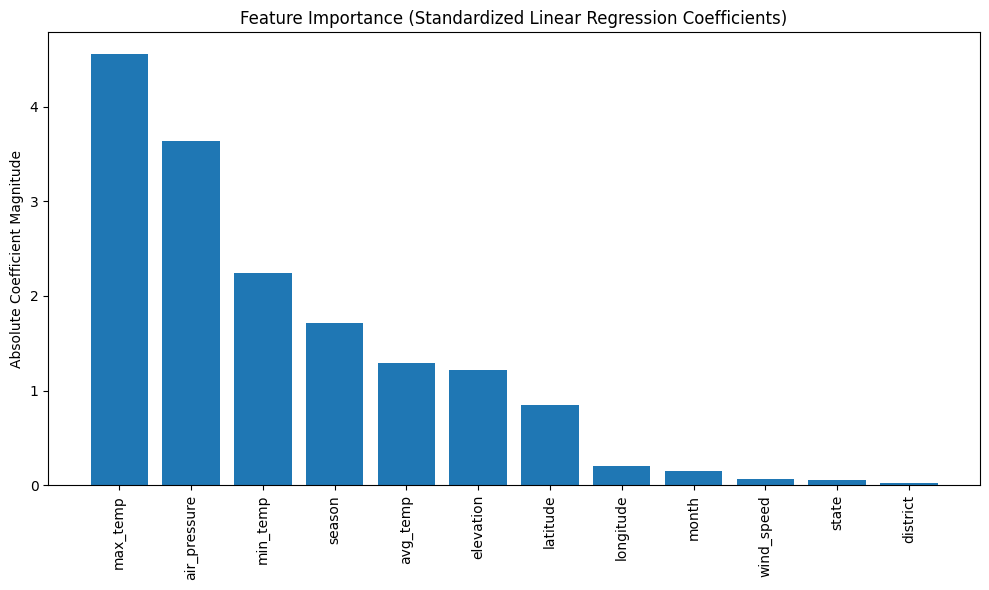

In [13]:
sample_df = df_select.sample(n=min(10000, len(df_select)), random_state=42)
X_sample = sample_df.drop('rainfall', axis=1)
y_sample = sample_df['rainfall']


scaler = StandardScaler()
X_sample_scaled = scaler.fit_transform(X_sample)


model_lr = LinearRegression()
model_lr.fit(X_sample_scaled, y_sample)


importances = np.abs(model_lr.coef_)
indices = np.argsort(importances)[::-1]


plt.figure(figsize=(10, 6))
plt.title("Feature Importance (Standardized Linear Regression Coefficients)")
plt.bar(range(X_sample.shape[1]), importances[indices], align="center")


plt.xticks(range(X_sample.shape[1]), X_sample.columns[indices], rotation=90)
plt.ylabel("Absolute Coefficient Magnitude")
plt.tight_layout()
plt.show()

# Perform PCA

Total Features: 12
Performing PCA as features > 5...
Original Feature Count: 12
Reduced Feature Count (PCA): 9
Explained Variance Ratio: 0.9633


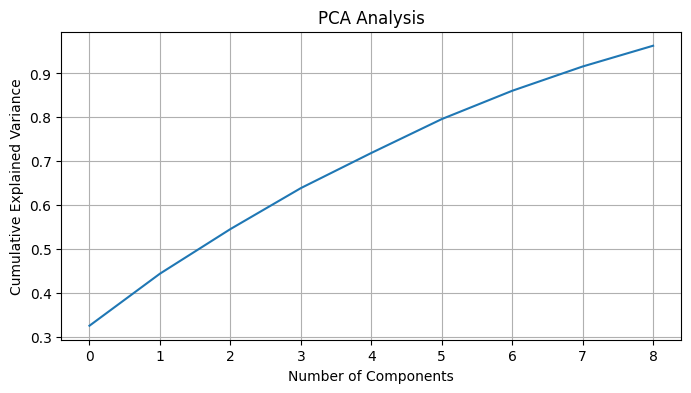

In [14]:
print(f"Total Features: {len(X.columns)}")

if len(X.columns) > 5:
    print("Performing PCA as features > 5...")
    
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca = PCA(n_components=0.95) 
    X_pca = pca.fit_transform(X_scaled)
    
    print(f"Original Feature Count: {X.shape[1]}")
    print(f"Reduced Feature Count (PCA): {X_pca.shape[1]}")
    print(f"Explained Variance Ratio: {np.sum(pca.explained_variance_ratio_):.4f}")
    
    plt.figure(figsize=(8, 4))
    plt.plot(np.cumsum(pca.explained_variance_ratio_))
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.title('PCA Analysis')
    plt.grid(True)
    plt.show()

# Linear Regression

Original Data Size: (712785, 13)
Super Optimized Data Size (85% retention): (606289, 13)
Max Rainfall in optimized data: 9.8

Regression Evaluation Metrics:
MAE: 1.3056
MSE: 3.7452
RMSE: 1.9352
R2 Score: 0.2091


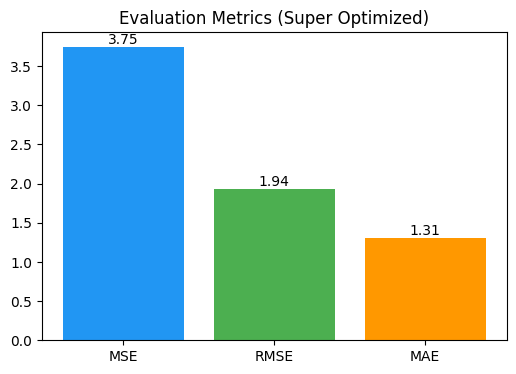

In [15]:
q_low = df_select['rainfall'].quantile(0.0)
q_high = df_select['rainfall'].quantile(0.85)
df_super_opt = df_select[(df_select['rainfall'] >= q_low) & (df_select['rainfall'] <= q_high)]

print(f"Original Data Size: {df_select.shape}")
print(f"Super Optimized Data Size (85% retention): {df_super_opt.shape}")
print(f"Max Rainfall in optimized data: {df_super_opt['rainfall'].max()}")


X_super = df_super_opt.drop('rainfall', axis=1)
y_super = df_super_opt['rainfall']


X_train, X_test, y_train, y_test = train_test_split(X_super, y_super, test_size=0.2, random_state=42)


lr_model = LinearRegression()
lr_model.fit(X_train, y_train)


y_pred = lr_model.predict(X_test)


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nRegression Evaluation Metrics:")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")


plt.figure(figsize=(6, 4))
bars = plt.bar(['MSE', 'RMSE', 'MAE'], [mse, rmse, mae], color=['#2196F3', '#4CAF50', '#FF9800'])
plt.title('Evaluation Metrics (Super Optimized)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), va='bottom', ha='center')
plt.show()

# Plot Original vs Predicted

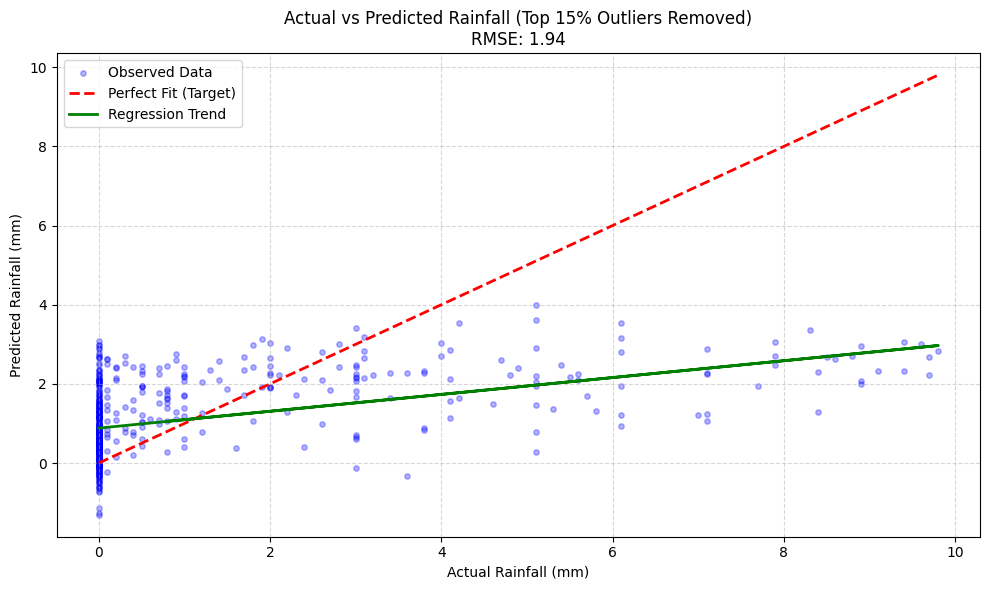

In [16]:
plt.figure(figsize=(10, 6))


plt.scatter(y_test[:500], y_pred[:500], color='blue', alpha=0.3, s=15, label='Observed Data')


limit_max = max(y_test.max(), y_pred.max())
plt.plot([0, limit_max], [0, limit_max], 'r--', linewidth=2, label='Perfect Fit (Target)')


m, b = np.polyfit(y_test, y_pred, 1)
plt.plot(y_test, m*y_test + b, color='green', linewidth=2, label='Regression Trend')


plt.title(f'Actual vs Predicted Rainfall (Top 15% Outliers Removed)\nRMSE: {rmse:.2f}', fontsize=12)
plt.xlabel('Actual Rainfall (mm)')
plt.ylabel('Predicted Rainfall (mm)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

# Prediction Pipeline

In [17]:
def predict_rainfall(input_data):
    
    input_df = pd.DataFrame([input_data])
    
    try:
        prediction = lr_model.predict(input_df)
        return prediction[0]
    except Exception as e:
        return f"Error: {str(e)}"


print("--- Prediction Pipeline Test ---")
sample_input = X_test.iloc[0].to_dict()
print("Input Features:", sample_input)
predicted_val = predict_rainfall(sample_input)
print(f"\nPredicted Rainfall: {predicted_val:.2f} mm")
print(f"Actual Rainfall: {y_test.iloc[0]:.2f} mm")

--- Prediction Pipeline Test ---
Input Features: {'month': 8.0, 'season': 2.0, 'state': 15.0, 'district': 143.0, 'avg_temp': 32.3, 'min_temp': 24.9, 'max_temp': 38.2, 'wind_speed': 8.5, 'air_pressure': 1009.7, 'elevation': 11.0, 'latitude': 11.8333, 'longitude': 75.3333}

Predicted Rainfall: 0.28 mm
Actual Rainfall: 0.80 mm
